# Notebook 2: knowledge distillation, teacher -> YOLOv8-seg (train, evaluate, save)

This notebook builds the **segmentation model that runs on the Raspberry Pi**:

```
folder tree of videos (searched through every sub-folder; optionally 3840 x 2160 only)
   -> STAGE 1: find the pen in each video ("animal pen" prompt)  -> crop it at full resolution
   -> STAGE 2: teacher masks on the crop (broiler / feeder; no scale)  [SAM 3 or Grounded SAM 2]
   -> YOLO-seg dataset of pen crops, split by video or by sub-folder
   -> train YOLOv8n-seg -> evaluate on held-out videos -> export NCNN / ONNX
   -> SAVE the model folder  ->  used by Notebook 3 (YOLO segmentation + fitted weight)
```

Weight estimation is **not** done here. Notebook 3 loads the model saved at the end of this notebook. The pen region is saved with the model, so Notebook 3 and the Raspberry Pi crop frames the same way automatically.

Set `DRY_RUN = True` to try it on generated nested folders of videos first.

## 0. Install (run once, then restart the kernel)

In [1]:
INSTALL = True                  # True = install / update broilerseg from GitHub, then restart
BRANCH = "main"               # branch
SUBDIR = "broilerseg"          # folder in the repo that holds pyproject.toml ("" = pick from a list)

if INSTALL:
    import shutil, subprocess, sys
    from pathlib import Path
    REPO = "https://github.com/Akintanoreofe/BroilerWeightEstimation.git"
    SRC = Path.home() / "broilerseg_src"
    shutil.rmtree(SRC, ignore_errors=True)
    r = subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO, str(SRC)],
                       capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr)
    cands = sorted(p.parent.relative_to(SRC) for p in SRC.rglob("pyproject.toml")
                   if 'name = "broilerseg"' in p.read_text(errors="ignore"))
    print("broilerseg folders on the branch:", [str(c) for c in cands])
    pkg = SRC / SUBDIR if SUBDIR else SRC / cands[int(input(f"Pick 1-{len(cands)}: ")) - 1]
    if not (pkg / "pyproject.toml").is_file():
        raise FileNotFoundError(f"No pyproject.toml directly inside '{pkg.relative_to(SRC)}'")
    for cmd in ([sys.executable, "-m", "pip", "install", f"{pkg}[all]"],
                [sys.executable, "-m", "pip", "install", "--force-reinstall", "--no-deps", str(pkg)]):
        r = subprocess.run(cmd, capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(r.stderr[-2500:])
    print("Installed from", pkg.relative_to(SRC), "- now restart the kernel and set INSTALL = False")

broilerseg folders on the branch: ['broilerseg']
Installed from broilerseg - now restart the kernel and set INSTALL = False


## Settings

In [12]:
# ---- data ---------------------------------------------------------------------------
DRY_RUN = False
TEACHER = "sam3"                 # "sam3", "grounded_sam2" or "mixed" (a teacher per class, below)
MIXED_TEACHER = {"broiler": "sam3", "feeder": "grounded_sam2"}  # used when TEACHER = "mixed"
COMPARE_TEACHERS = False         # True = show SAM 3 vs Grounded SAM 2 on a few pen crops (loads both)
# The weighing scale is NOT segmented (SAM 3 was unreliable on it): YOLO learns broiler + feeder only.
# Label files made by earlier versions are reused as they are (their scale masks are ignored).
TEACHER_MAX_SIDE = 1280          # the crop is resized to at most this before the teacher runs
ONLY_RESOLUTION = (3840, 2160)   # label only videos of this size (None = every size)
MAX_VIDEOS = 1000                # use at most this many videos, spread evenly over all folders (None = all)
FRAMES_PER_VIDEO = 1           # frames the teacher labels per video
SECONDS_PER_FRAME = 1           # teacher time per frame on your Mac (you measured ~8.6 s), for the time estimate
SAMPLING = "uniform"             # "uniform", "random" or "motion" (busiest frames)
SKIP_START = 0                   # ignore the first N frames of each video
MIN_TEACHER_SCORE = 0.4          # drop low-confidence teacher masks from the training labels
# ---- stage 1: crop to the pen ------------------------------------------------------------
USE_PEN_CROP = True              # False = old one-stage labelling of the whole frame
PEN_PROMPTS = ("animal pen", "wood shavings bedding", "fenced enclosure")  # text prompts for the pen
PEN_PREFER = "score"             # several prompts hit: "score" (most confident) or "largest"
PEN_SCOPE = "video"              # "video" (one region per video) or "folder" (one per sub-folder: faster)
PEN_FRAMES = 2                   # frames looked at per video (or per folder)
PEN_MARGIN = 0.03                # extra border around the pen (fraction of the frame)
PEN_MASK_OUTSIDE = False         # True = also grey out what is inside the box but outside the pen
MANUAL_PEN_BOXES = {}            # fix a region by hand: {"2025-09-27/ch00_3840x2160": (x0, y0, x1, y1)}
                                 # pixels of that video's frames; a folder covers its sub-folders; "*" = all
COMPARE_ONE_STAGE = True         # show the teacher on the whole frame vs on the crop (one frame)
# ---- dataset split -------------------------------------------------------------------
SPLIT_BY = "video"               # "video" or "folder" (whole sub-folders held out: harder test)
VAL_FRACTION = 0.15              # share of videos / folders for validation
TEST_FRACTION = 0.15             # share for a final test, never used during training
# ---- training ------------------------------------------------------------------------
RUN_TRAINING = True
BASE_MODEL = "yolov8n-seg.pt"    # nano = Raspberry-Pi size; "yolov8s-seg.pt" if accuracy is short
EPOCHS = 30
PATIENCE = 5                    # stop early when validation stops improving
IMGSZ = 640                      # use the size you will run on the Pi (320 / 480 are faster)
BATCH = 8                        # 8 keeps memory low on a Mac (16 led to swapping + NMS time-outs)
CACHE = "ram"                    # keep resized training images in memory (much faster epochs)
EXPORT_FORMATS = ("ncnn", "onnx")
# ---- where things go -----------------------------------------------------------------
MODEL_NAME = "broiler_yolov8n_seg"
MODELS_DIR = "~/broilerseg_models"                 # the saved model folder goes here
OUTPUT_DIR = "~/broilerseg_outputs/02_distillation"
SEED = 0
SAVE_FIGURES = True
# ---------------------------------------------------------------------------------------

In [13]:
import json
import warnings
from datetime import datetime
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import broilerseg
from broilerseg import viz
from broilerseg.config import CLASS_NAMES, PromptConfig
from broilerseg.distill import (benchmark, evaluate_student, export_for_raspberry_pi,
                                load_training_curves, path_size_mb, save_student,
                                teacher_student_table, train_student)
from broilerseg.io import motion_scores, read_frame, scan_videos
from broilerseg.io.video import safe_read_frame
from broilerseg.labeling import (LazyResults, auto_label_videos, count_labels, load_frames_lazily,
                                 load_result, plan_sampling)
from broilerseg.roi import (PenDetector, apply_manual_rois, choose_pen, find_pen_rois, rois_lookup,
                            save_rois, typical_roi)
from broilerseg.notebook import ask_for_directory, environment_report
from broilerseg.yolo_dataset import build_yolo_dataset

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
viz.set_style()
OUT = Path(OUTPUT_DIR).expanduser().resolve(); (OUT / "figures").mkdir(parents=True, exist_ok=True)
MODELS = Path(MODELS_DIR).expanduser().resolve(); MODELS.mkdir(parents=True, exist_ok=True)
FIG = 0
def show(fig, name):
    global FIG
    FIG += 1
    if SAVE_FIGURES:
        viz.save(fig, OUT / "figures" / f"{FIG:02d}_{name}.png")
    plt.show()
try:
    import ultralytics  # noqa: F401
    HAVE_ULTRALYTICS = True
except ImportError:
    HAVE_ULTRALYTICS = False
print("broilerseg", broilerseg.__version__, "| ultralytics:", HAVE_ULTRALYTICS)
if broilerseg.__version__ < "0.6.0":
    print("This notebook needs broilerseg >= 0.6.0 (broiler + feeder only, two-stage pen crop) - set INSTALL = True above, "
          "run it, restart.")
display(pd.Series(environment_report(), name="environment").to_frame())

broilerseg 0.6.2 | ultralytics: True


,environment
python,3.12.5
platform,macOS-26.6.2-arm64-arm-64bit
numpy,2.0.2
cv2,4.12.0
torch,2.8.0
transformers,5.14.1
ultralytics,8.4.115
cuda,False
mps,True


Counting labels:   0%|          | 0/1000 [00:00<?, ?it/s]

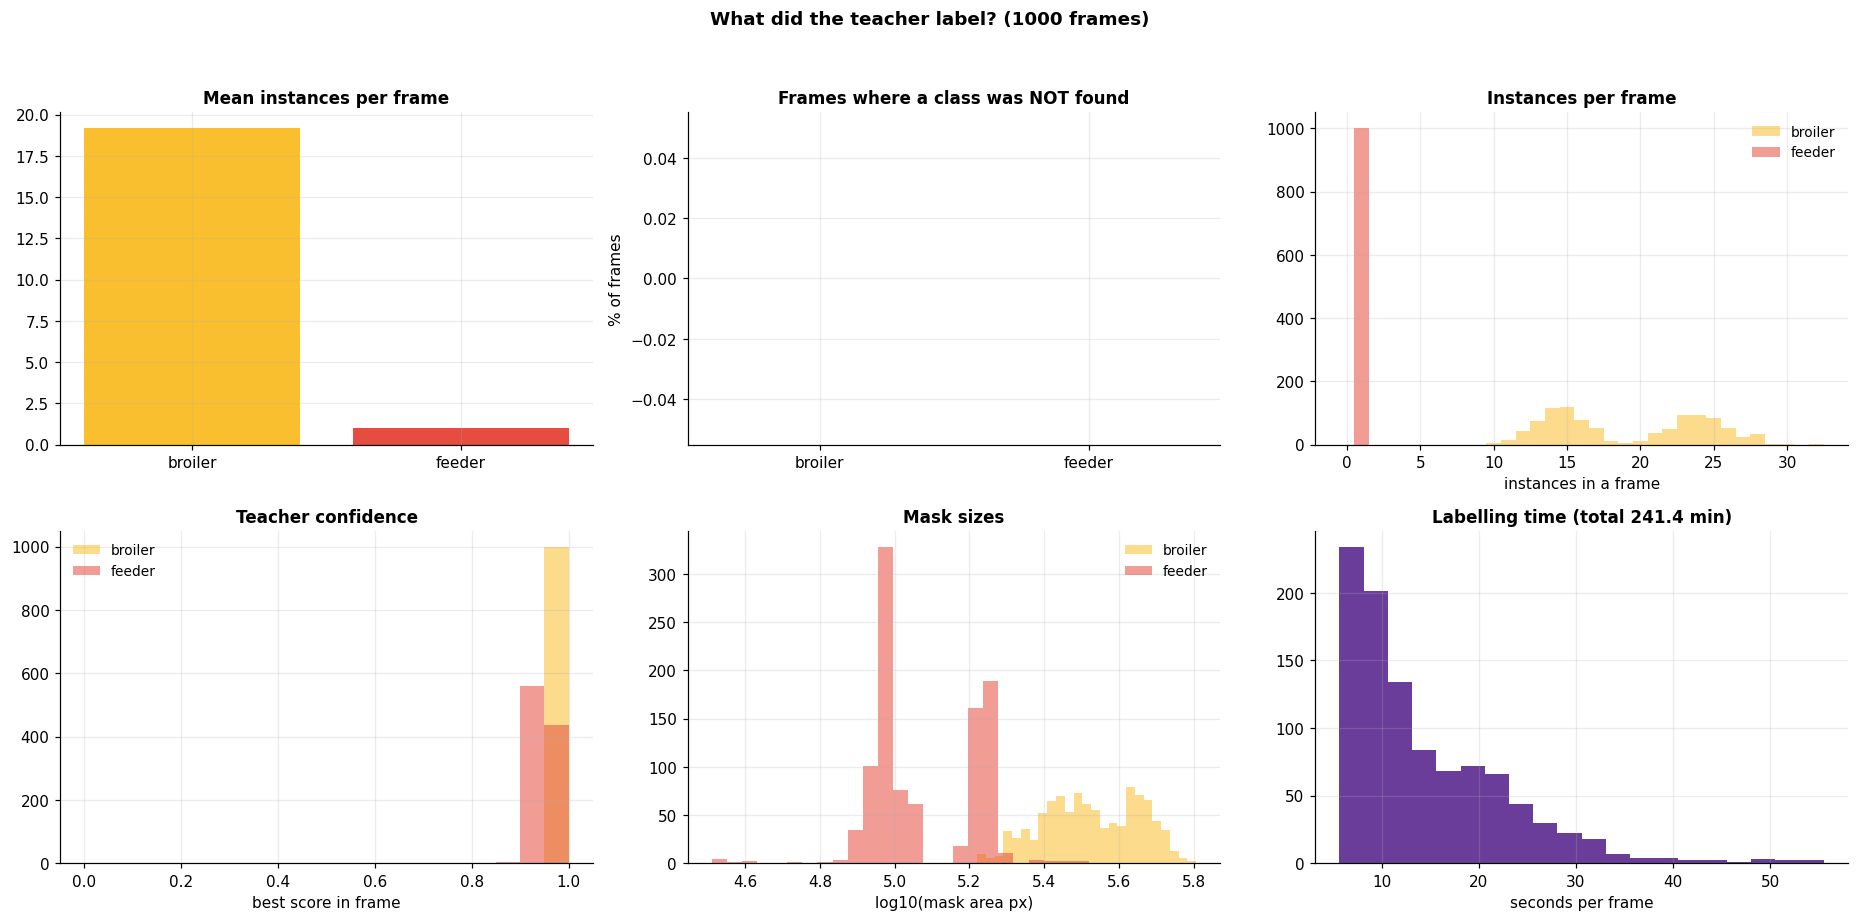

1000 labelled frames | 0 without a single feeder
Continue with section 5 (build the dataset), then training


In [4]:
# ---- RESUME after a kernel restart (memory-safe): run this instead of sections 1-3 ---
from broilerseg.roi import load_rois
from broilerseg.labeling import frame_stem, LazyResults, count_labels

VIDEO_DIR = Path("/Users/akintanoreofeoluwa/Dahua_2025/Contains broilers")
LABEL_DIR = OUT / ("labels_pen" if USE_PEN_CROP else "labels")
prompts = PromptConfig()

plan = pd.read_csv(OUT / "sampling_plan.csv")
rois = load_rois(OUT / "pen_rois.csv") if USE_PEN_CROP else None
PEN_ROI = typical_roi(rois) if rois is not None else None
videos = rois if rois is not None else plan.rename(
    columns={"video_stem": "video_id", "video": "path"}).drop_duplicates("video_id")
if "folder" not in videos:
    videos = videos.assign(folder=".")
frame0 = next((f for f in (safe_read_frame(p, 30) for p in videos.path.head(5)) if f is not None), None)

teacher = None                                     # loaded again automatically after training
manifest = pd.read_csv(LABEL_DIR / "manifest.csv")
def load_frame(stem):
    return cv2.cvtColor(cv2.imread(str(LABEL_DIR / "frames" / f"{stem}.jpg")), cv2.COLOR_BGR2RGB)
teacher_results = LazyResults(LABEL_DIR, manifest.stem)        # read from disk only when used
counts = count_labels(LABEL_DIR, manifest.stem)                # one file at a time
manifest = manifest.drop(columns=[c for c in counts if c != "stem" and c in manifest]).merge(counts, on="stem")
show(viz.plot_label_statistics(manifest), "label_statistics")
print(f"{len(manifest)} labelled frames | {(manifest.n_feeder != 1).sum()} without a single feeder")
print("Continue with section 5 (build the dataset), then training")

## 1. The folder tree of videos

Paste the **top** folder. Every sub-folder is searched, however deep. Videos with the same file name in different folders (e.g. `ch01.mp4` in every day-folder) are told apart by their path: `day1__cam2__ch01`. To skip the prompt, set the `BROILERSEG_VIDEO_DIR` environment variable.

In [ ]:
if DRY_RUN:
    from broilerseg.synthetic import make_demo_data
    demo = make_demo_data(OUT / "demo_data", n_events=8, frames_per_event=30, nested=True)
    VIDEO_DIR = demo["videos"]
    print("DRY RUN: synthetic nested folders in", VIDEO_DIR)
else:
    VIDEO_DIR = ask_for_directory("Paste the TOP folder that contains the video sub-folders",
                                  env_var="BROILERSEG_VIDEO_DIR")
videos = scan_videos(VIDEO_DIR)
if videos.empty:
    raise FileNotFoundError(f"No videos found anywhere under {VIDEO_DIR}")
print(f"{len(videos)} videos in {videos.folder.nunique()} folders "
      f"({videos.duration_s.sum() / 60:.1f} min, {videos.size_mb.sum():.0f} MB)")
display(videos[["video_id", "folder", "name", "n_frames", "fps", "width", "height", "duration_s"]].head(20))
show(viz.plot_folder_summary(videos), "folders")
res_counts = videos.assign(res=videos.width.astype(str) + " x " + videos.height.astype(str)).res.value_counts()
fig, ax = plt.subplots(figsize=(7, 0.5 + 0.45 * len(res_counts)))
ax.barh(res_counts.index[::-1], res_counts.values[::-1], color="tab:blue")
for i, v in enumerate(res_counts.values[::-1]):
    ax.text(v, i, f" {v}", va="center")
ax.set(xlabel="videos", title="Video resolutions found"); fig.tight_layout()
show(fig, "resolutions")
if ONLY_RESOLUTION and not DRY_RUN:
    W, H = ONLY_RESOLUTION
    keep = (videos.width == W) & (videos.height == H)
    print(f"ONLY_RESOLUTION = {W} x {H}: keeping {int(keep.sum())} of {len(videos)} videos")
    videos = videos[keep].reset_index(drop=True)
    if videos.empty:
        raise ValueError(f"No {W} x {H} videos - check ONLY_RESOLUTION (None = every size)")
all_videos = videos
if MAX_VIDEOS and len(videos) > MAX_VIDEOS:
    # round-robin over folders so every folder contributes before any gets a second video
    order = (videos.sort_values(["folder", "rel_path"])
             .assign(_k=lambda d: d.groupby("folder").cumcount())
             .sort_values(["_k", "folder"]))
    videos = order.head(MAX_VIDEOS).drop(columns="_k").sort_values("rel_path").reset_index(drop=True)
    print(f"Using {len(videos)} of {len(all_videos)} videos, from {videos.folder.nunique()} of "
          f"{all_videos.folder.nunique()} folders (raise MAX_VIDEOS to use more)")
show(viz.plot_video_inventory(videos.assign(stem=videos.video_id)), "video_inventory")
firsts = videos.groupby("folder").head(1).head(15)
show(viz.plot_contact_sheet([read_frame(p, min(10, max(0, n - 1))) for p, n in zip(firsts.path, firsts.n_frames)],
                            list(firsts.folder), title="One frame from each folder"), "contact_sheet")

## 2. Stage 1: find the pen and crop it

The camera sees much more than the pen: the floor around it, the desk, the computer and cables. On the whole frame the teacher confuses the feeder and birds with clutter. A 16:9 4K frame squeezed into the teacher's square input also leaves each bird only a few pixels wide.

```
full 4K frame --[stage 1: "animal pen" prompt]--> pen box (+ outline)
              --[crop at FULL resolution]-------> pen crop (about 2000 x 2160 px)
              --[stage 2: broiler / feeder]-----> masks used for training
```

The crop is cut at full resolution and never rescaled, so the feeder still sets the pixel-to-cm scale exactly as before. The same teacher model does both stages (only the text prompt changes), so nothing extra is loaded.

**Check the plots below.** If the pen is missed or the box is wrong for some folder, try other `PEN_PROMPTS`, or set a box by hand in `MANUAL_PEN_BOXES` (pixel coordinates are shown on the axes of the first plot).

In [ ]:
prompts = PromptConfig()
if DRY_RUN:
    from broilerseg.synthetic import ColorPenDetector, ColorSegmenter
    teacher, pen_detector = ColorSegmenter(), ColorPenDetector()
else:
    from broilerseg.segmentation import load_teacher
    from broilerseg.segmentation import load_mixed_teacher
    if TEACHER == "mixed":    # stage 1 (the pen) uses the broiler teacher
        teacher = load_mixed_teacher(MIXED_TEACHER, prompts=prompts, default="broiler",
                                     max_side=TEACHER_MAX_SIDE)
    else:
        teacher = load_teacher(TEACHER, prompts=prompts, max_side=TEACHER_MAX_SIDE)
    pen_detector = PenDetector(teacher, PEN_PROMPTS)
    print(teacher.name, "on", teacher.device)
v0 = videos.iloc[0]
frame0 = safe_read_frame(v0.path, int(v0.n_frames or 0) // 2)    # tolerant of damaged files
cands = pen_detector.segment(frame0)
chosen = choose_pen(cands, prefer=PEN_PREFER)
print(f"{len(cands.of_class('pen'))} pen candidates in {v0.video_id}, {cands.seconds:.1f} s")
show(viz.plot_pen_candidates(frame0, cands, chosen, title=f"Stage 1 candidates in {v0.video_id}"),
     "pen_candidates")
fig, ax = plt.subplots(figsize=(12, 6.75))
ax.imshow(frame0); ax.set_title(f"{v0.video_id}: pixel grid for MANUAL_PEN_BOXES "
                                f"({frame0.shape[1]} x {frame0.shape[0]})")
ax.set_xticks(np.arange(0, frame0.shape[1] + 1, frame0.shape[1] // 16))
ax.set_yticks(np.arange(0, frame0.shape[0] + 1, frame0.shape[0] // 9))
ax.tick_params(axis="x", rotation=90, labelsize=7); ax.tick_params(axis="y", labelsize=7)
ax.grid(True, color="white", alpha=0.35, lw=0.6); fig.tight_layout()
show(fig, "pixel_grid")

In [ ]:
rois, PEN_ROI = None, None
if USE_PEN_CROP:
    rois = find_pen_rois(videos, pen_detector, PEN_FRAMES, PEN_SCOPE, PEN_MARGIN, prefer=PEN_PREFER,
                         cache=OUT / "pen_rois_auto.csv")        # resumable, like the labelling
    rois = apply_manual_rois(rois, MANUAL_PEN_BOXES)
    save_rois(rois, OUT / "pen_rois.csv")
    PEN_ROI = typical_roi(rois)
    print(f"Pen regions for {len(rois)} videos -> {OUT / 'pen_rois.csv'}")
    display(rois.method.value_counts().rename("videos").to_frame())
    display(rois[["video_id", "method", "score", "x0", "y0", "x1", "y1", "crop_width", "crop_height"]]
            .head(15).round(3))
    show(viz.plot_roi_summary(rois), "roi_summary")
    look = rois_lookup(rois)
    picks = videos.groupby("folder").head(1).head(15)
    frames = [safe_read_frame(p, int(n or 0) // 2) for p, n in zip(picks.path, picks.n_frames)]
    ok = [f is not None for f in frames]
    frames, picks = [f for f in frames if f is not None], picks[ok]
    show(viz.plot_pen_rois(frames, [look[v] for v in picks.video_id], list(picks.folder)), "pen_rois")
    show(viz.plot_pen_crops(frames, [look[v] for v in picks.video_id], list(picks.folder),
                            mask_outside=PEN_MASK_OUTSIDE), "pen_crops")
    odd = rois[rois.method.isin(["folder_median", "full_frame"])]
    if len(odd):
        print(f"{len(odd)} videos had no pen found and got a fallback region - check them, or add "
              f"MANUAL_PEN_BOXES:"); display(odd[["video_id", "folder", "method"]].head(20))
else:
    print("USE_PEN_CROP = False: the teacher labels whole frames (one stage)")

In [ ]:
if USE_PEN_CROP and COMPARE_ONE_STAGE:
    roi0 = rois_lookup(rois)[v0.video_id]
    crop0 = roi0.crop(frame0, PEN_MASK_OUTSIDE)
    one_stage, two_stage = teacher.segment(frame0), teacher.segment(crop0)
    show(viz.plot_two_stage(frame0, one_stage, roi0, crop0, two_stage,
                            title=f"{v0.video_id}: one stage vs two stages"), "one_vs_two_stage")
    display(pd.DataFrame({"one stage (whole frame)": one_stage.counts(),
                          "two stages (pen crop)": two_stage.counts()}).T
            .assign(seconds=[one_stage.seconds, two_stage.seconds]).round(2))
    print(f"Each bird gets about {frame0.shape[1] / crop0.shape[1]:.1f}x more pixels in stage 2 "
          f"(crop {crop0.shape[1]} x {crop0.shape[0]} of {frame0.shape[1]} x {frame0.shape[0]})")

In [ ]:
# Which teacher finds the birds and the feeder better? Same pen crops, both models.
if COMPARE_TEACHERS and USE_PEN_CROP and not DRY_RUN:
    from broilerseg.segmentation import load_teacher
    from broilerseg.segmentation.mixed import MixedTeacher
    have = ({type(t).__name__: t for t in teacher.teachers.values()} if isinstance(teacher, MixedTeacher)
            else {type(teacher).__name__: teacher})
    models = {
        "SAM 3": have.get("Sam3Segmenter") or load_teacher("sam3", prompts=prompts, max_side=TEACHER_MAX_SIDE),
        "Grounded SAM 2": have.get("GroundedSam2Segmenter")
        or load_teacher("grounded_sam2", prompts=prompts, max_side=TEACHER_MAX_SIDE),
    }
    look = rois_lookup(rois)
    picks = videos.sample(min(4, len(videos)), random_state=SEED)
    crops = []
    for r in picks.itertuples():
        f = safe_read_frame(r.path, int(r.n_frames or 0) // 2)
        if f is not None:
            crops.append(look[r.video_id].crop(f, PEN_MASK_OUTSIDE))
    rows = []
    for cls in ("broiler", "feeder"):
        fig, axes = plt.subplots(len(models), len(crops), figsize=(4.2 * len(crops), 4.0 * len(models)),
                                 squeeze=False)
        for i, (mname, m) in enumerate(models.items()):
            old = m.prompts
            m.prompts = PromptConfig(prompts={cls: prompts.prompts[cls]},
                                     score_threshold=prompts.score_threshold,
                                     mask_threshold=prompts.mask_threshold)
            try:
                for j, crop in enumerate(crops):
                    res = m.segment(crop)
                    found = res.of_class(cls)
                    best = max((x.score for x in found), default=0.0)
                    rows.append({"class": cls, "teacher": mname, "n_found": len(found),
                                 "best_score": best, "seconds": res.seconds})
                    viz.plot_overlay(crop, res, ax=axes[i, j], show_boxes=False,
                                     title=f"{mname}: n={len(found)} best={best:.2f}")
                    if cls == "feeder":
                        axes[i, j].title.set_color("green" if len(found) == 1 else "red")
            finally:
                m.prompts = old
        fig.suptitle(f"{cls}: SAM 3 (top) vs Grounded SAM 2 (bottom)"
                     + ("; green = exactly one found" if cls == "feeder" else ""),
                     fontweight="bold"); fig.tight_layout()
        show(fig, f"teacher_compare_{cls}")
    cmp = (pd.DataFrame(rows).groupby(["class", "teacher"])
           .agg(crops_with_exactly_one=("n_found", lambda n: int((n == 1).sum())),
                mean_best_score=("best_score", "mean"), seconds=("seconds", "mean")))
    display(cmp.round(2))
    print('Pick the better teacher per class and set TEACHER = "mixed" with MIXED_TEACHER accordingly.')

## 3. Which frames to label

In [ ]:
plan = plan_sampling(videos, FRAMES_PER_VIDEO, SAMPLING, SEED, SKIP_START)
plan.to_csv(OUT / "sampling_plan.csv", index=False)
hours = len(plan) * SECONDS_PER_FRAME / 3600   # stage 1 was already done above
print(f"{len(plan)} frames from {plan.video.nunique()} videos -> about {hours:.1f} h of teacher "
      f"labelling at {SECONDS_PER_FRAME} s/frame (resumable: you can stop and re-run)")
show(viz.plot_sampling_plan(plan), "sampling_plan")
v0 = videos.iloc[0]
mo = motion_scores(v0.path, stride=max(1, int(v0.n_frames) // 300))
show(viz.plot_motion_profile(mo, plan[plan.video == v0.path].frame_idx.tolist(),
                             title=f"Activity in {v0.video_id}"), "motion_profile")

## 4. Stage 2: label the pen crops with the teacher

Each sampled frame is cropped to its video's pen, then the teacher segments broilers and the feeder **inside the crop** (the scale is not labelled; if the feeder comes out in pieces they are merged into one mask). The crops are what gets saved (and what YOLO trains on); the manifest records where each crop sits in the full frame (`roi_x0 ... roi_y1`).

Frames, masks (`.npz`), overlays and `manifest.csv` are written to `labels_pen/` (`labels/` without the crop, so the two never mix). **Re-running resumes**: frames that already have masks are skipped.

In [ ]:
LABEL_DIR = OUT / ("labels_pen" if USE_PEN_CROP else "labels")
manifest = auto_label_videos(VIDEO_DIR, LABEL_DIR, teacher, plan=plan,
                             rois=rois if USE_PEN_CROP else None, mask_outside=PEN_MASK_OUTSIDE)
print(f"{len(manifest)} frames labelled -> {LABEL_DIR}")
show(viz.plot_label_statistics(manifest), "label_statistics")
def load_frame(stem):
    return cv2.cvtColor(cv2.imread(str(LABEL_DIR / "frames" / f"{stem}.jpg")), cv2.COLOR_BGR2RGB)
# Read from disk only when used: full-resolution masks of every frame would need tens of GB
teacher_results = LazyResults(LABEL_DIR, manifest.stem)
# counts after merging feeder pieces (older labels stored 2-3 feeder pieces per frame)
counts = count_labels(LABEL_DIR, manifest.stem)
manifest = manifest.drop(columns=[c for c in counts if c != "stem" and c in manifest]).merge(counts, on="stem")
rng = np.random.default_rng(SEED)
stems = rng.choice(manifest.stem, size=min(12, len(manifest)), replace=False)
show(viz.plot_gallery([(load_frame(st), teacher_results[st], st[-24:]) for st in stems], ncols=4,
                      title=f"{teacher.name} pseudo-labels"), "teacher_gallery")
show(viz.plot_segmentation_panels(load_frame(stems[0]), teacher_results[stems[0]], stems[0]), "teacher_panels")
suspect = manifest[manifest.n_feeder != 1]
print(f"{len(suspect)} frames without a feeder (it sets the pixel-to-cm scale) - check these:")
if len(suspect):
    show(viz.plot_gallery([(load_frame(s), teacher_results[s], s[-24:]) for s in suspect.stem[:8]],
                          ncols=4, show_scores=True, title="Check these pseudo-labels"), "teacher_suspect")

## 5. Build the YOLO-seg dataset

Masks become polygons. With `SPLIT_BY = "video"`, whole videos go to train / val / test. With `"folder"`, whole sub-folders do: a harder and more honest test if folders are different days or cameras.

path: /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/yolo_dataset_2class
train: images/train
val: images/val
test: images/test
names:
  0: broiler
  1: feeder



,images,groups,broiler_polygons,feeder_polygons
split,,,,
test,150,150,3372,207
train,700,700,15518,983
val,150,150,3315,228


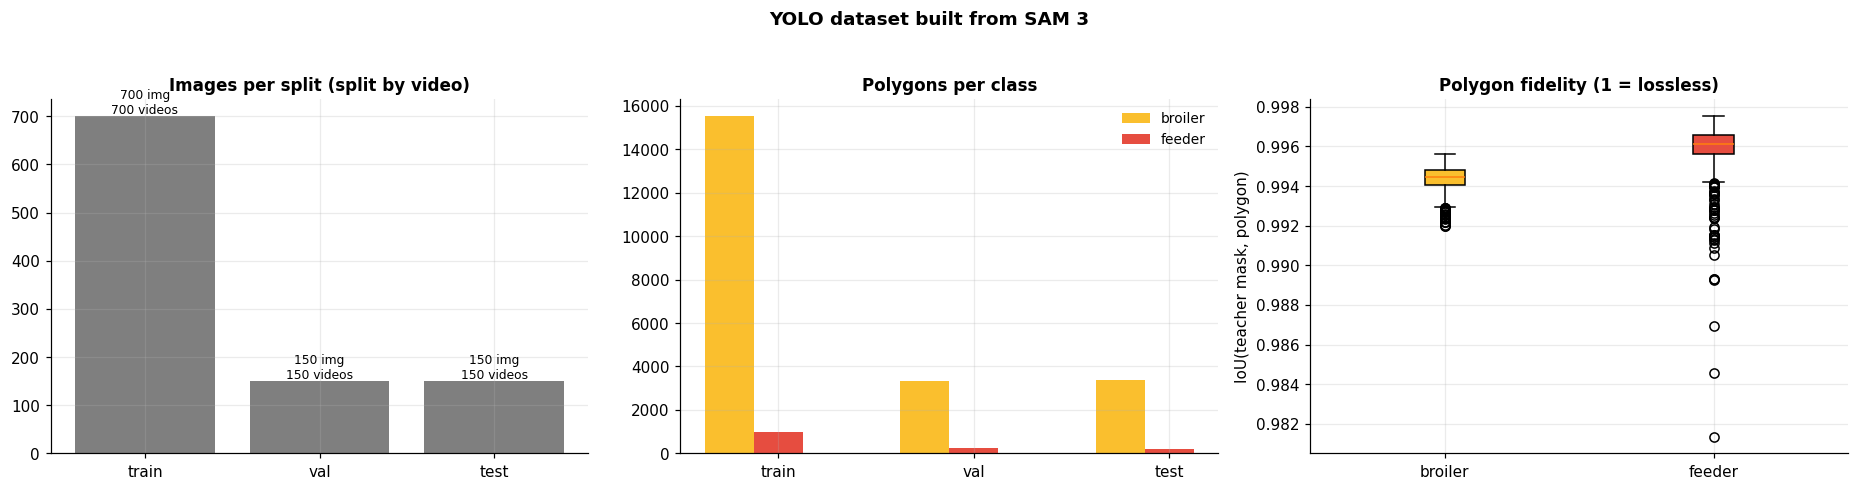

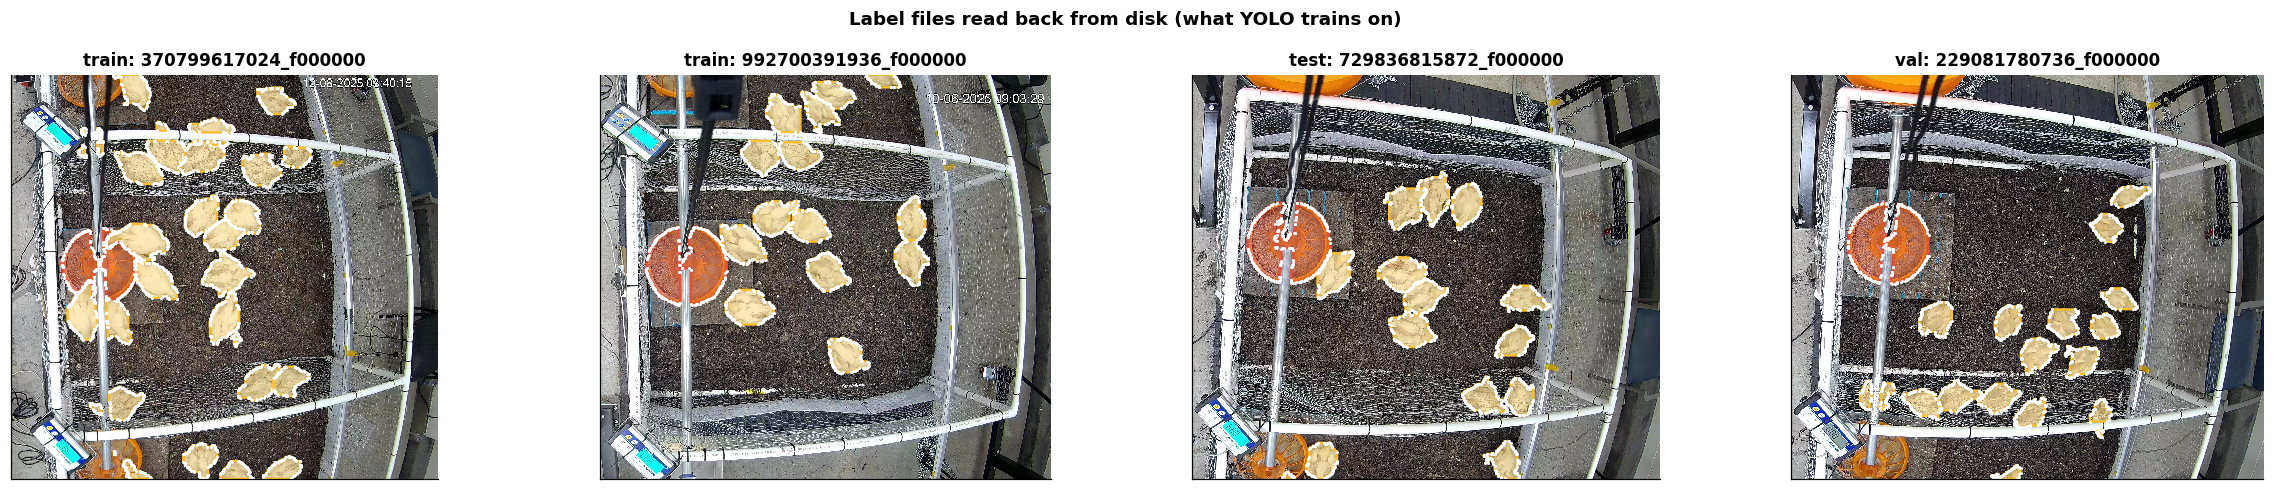

In [5]:
YOLO_DIR = OUT / "yolo_dataset_2class"    # broiler + feeder (the old 3-class dataset is left alone)
ds = build_yolo_dataset(LABEL_DIR, YOLO_DIR, (1 - VAL_FRACTION - TEST_FRACTION, VAL_FRACTION, TEST_FRACTION),
                        seed=SEED, min_score=MIN_TEACHER_SCORE, split_by=SPLIT_BY)
print((YOLO_DIR / "data.yaml").read_text())
display(ds.groupby("split").agg(images=("stem", "size"), groups=("split_group", "nunique"),
                                **{f"{c}_polygons": (f"n_{c}", "sum") for c in CLASS_NAMES}))
show(viz.plot_split_summary(ds), "split_summary")
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, (_, r) in zip(axes, ds.sample(min(4, len(ds)), random_state=SEED).iterrows()):
    viz.plot_yolo_label_check(YOLO_DIR / "images" / r.split / f"{r.stem}.jpg",
                              YOLO_DIR / "labels" / r.split / f"{r.stem}.txt", ax=ax,
                              title=f"{r.split}: {r.stem[-20:]}")
fig.suptitle("Label files read back from disk (what YOLO trains on)", fontweight="bold"); fig.tight_layout()
show(fig, "yolo_label_check")

## 6. Train the student (on the pen crops)

In [ ]:
RUN_DIR = None
if RUN_TRAINING and HAVE_ULTRALYTICS:
    # Free the teacher while YOLO trains: SAM 3 + training together made the Mac swap, which slowed
    # everything and made Ultralytics' NMS time out (the NMS limit itself is raised by train_student).
    import gc
    teacher, pen_detector = None, None
    gc.collect()
    try:
        import torch
        if torch.backends.mps.is_available():
            torch.mps.empty_cache()
    except ImportError:
        pass
    RUN_DIR = train_student(YOLO_DIR / "data.yaml", BASE_MODEL, EPOCHS, IMGSZ, BATCH,
                            project=OUT / "runs", name=MODEL_NAME, patience=PATIENCE, seed=SEED,
                            cache=CACHE)
    print("Run folder:", RUN_DIR)
    curves = load_training_curves(RUN_DIR)
    show(viz.plot_training_curves(curves), "training_curves")
    pngs = [p for p in sorted(Path(RUN_DIR).glob("*.png")) if not p.name.startswith("train_batch")][:9]
    if pngs:
        show(viz.plot_contact_sheet([cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB) for p in pngs],
                                    [p.name for p in pngs], ncols=3, size=5.5,
                                    title="Ultralytics plots"), "ultralytics_plots")
else:
    print("Training skipped" + ("" if HAVE_ULTRALYTICS else " (ultralytics not installed)"))

New https://pypi.org/project/ultralytics/8.4.219 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.115 🚀 Python-3.12.5 torch-2.8.0 MPS (Apple M3 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/yolo_dataset_2class/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_

In [ ]:
# Load the teacher again for the comparison and speed test below (it was freed for training)
if teacher is None:
    if DRY_RUN:
        from broilerseg.synthetic import ColorSegmenter
        teacher = ColorSegmenter()
    elif TEACHER == "mixed":
        from broilerseg.segmentation import load_mixed_teacher
        teacher = load_mixed_teacher(MIXED_TEACHER, prompts=prompts, default="broiler",
                                     max_side=TEACHER_MAX_SIDE)
    else:
        from broilerseg.segmentation import load_teacher
        teacher = load_teacher(TEACHER, prompts=prompts, max_side=TEACHER_MAX_SIDE)
print("Teacher:", teacher.name)

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

Teacher: SAM 3


## 7. Evaluate the student (on held-out pen crops)

1. **Ultralytics metrics** (mask and box mAP) on the validation and **test** videos, against the teacher's labels.
2. **Agreement with the teacher** on held-out frames: IoU per class, instance counts, and the frames where they disagree most.
3. **Speed and size** of the student vs the teacher, plus the Raspberry Pi exports.

Ultralytics 8.4.115 🚀 Python-3.12.5 torch-2.8.0 MPS (Apple M3 Pro)
YOLOv8n-seg summary (fused): 86 layers, 3,258,454 parameters, 0 gradients, 11.3 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 2266.4±400.0 MB/s, size: 2410.1 KB)
val: Scanning /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/yolo_dataset_2class/labels/val.cache... 214 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 214/214 24.3Mit/s 0.0s
val: /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/yolo_dataset_2class/images/val/2025-10-03__ch00_3840x2160__14__2025-10-03_14-21-47_to_14-21-49__ch00__SWF_1404770229760_f000000.jpg: 1 duplicate labels removed
val: /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/yolo_dataset_2class/images/val/2025-10-07__ch00_3840x2160__15__2025-10-07_15-02-46_to_15-02-47__ch00__SWF_2258655488000_f000000.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R    

,split,mask_mAP50,mask_mAP50-95,mask_precision,mask_recall,box_mAP50,box_mAP50-95,box_precision,box_recall
0,val,0.893,0.733,0.925,0.861,0.890,0.781,0.913,0.860
1,test,0.897,0.739,0.923,0.851,0.894,0.789,0.913,0.843


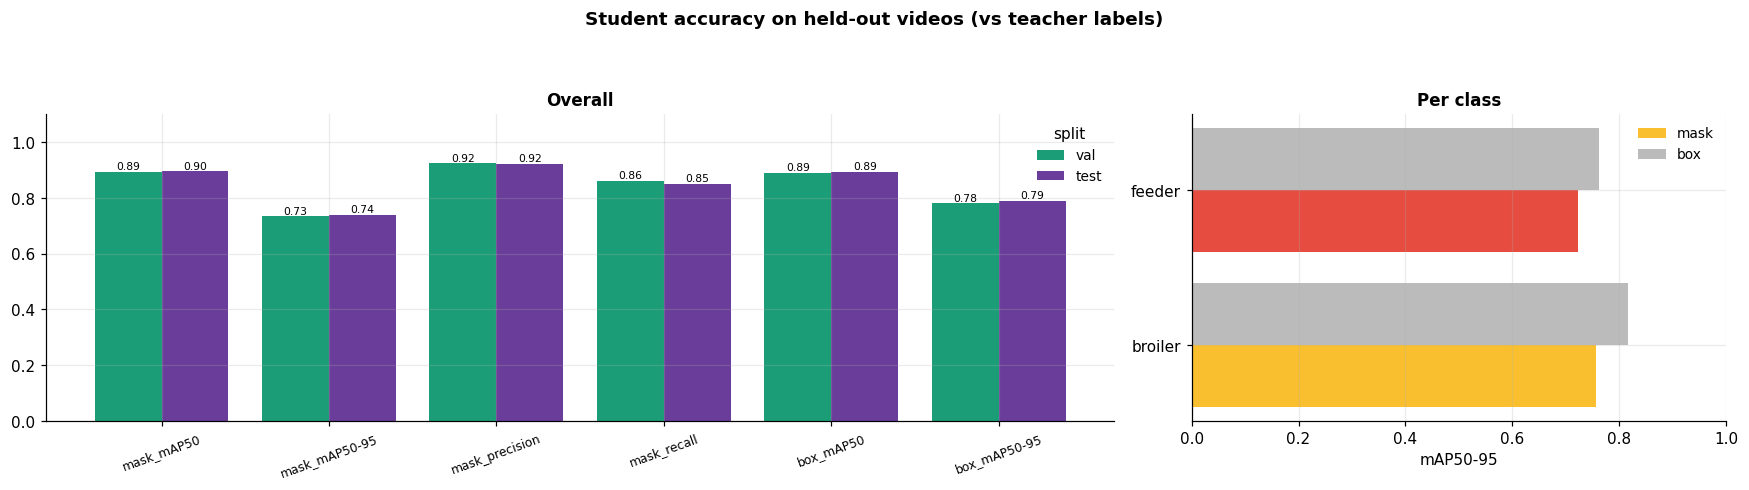

,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
broiler,150.0,0.893,0.015,0.813,0.884,0.893,0.904,0.918
feeder,150.0,0.864,0.164,0.395,0.908,0.932,0.939,0.956


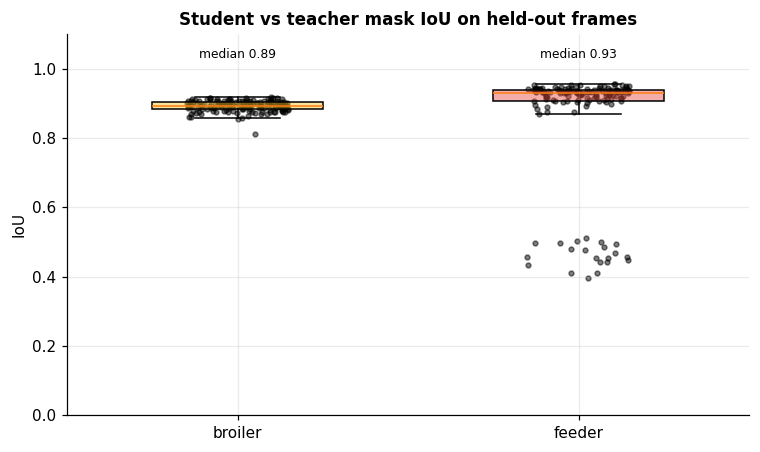

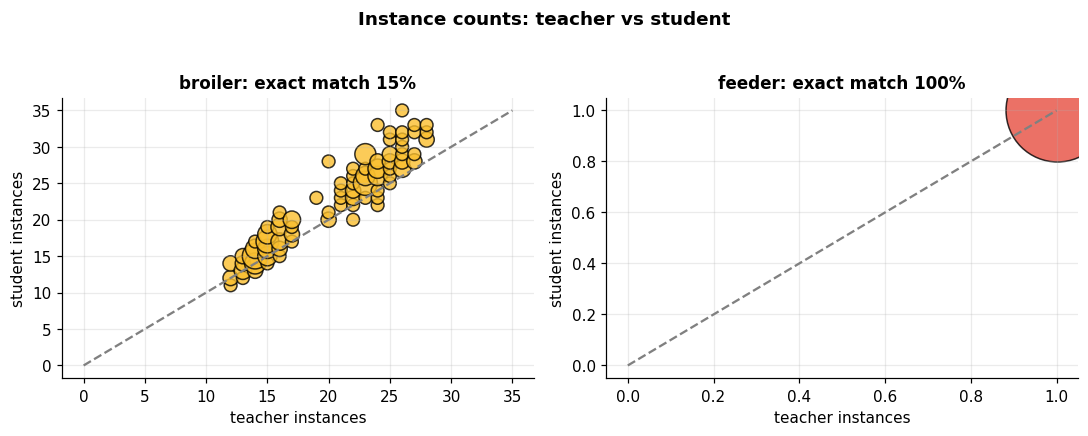

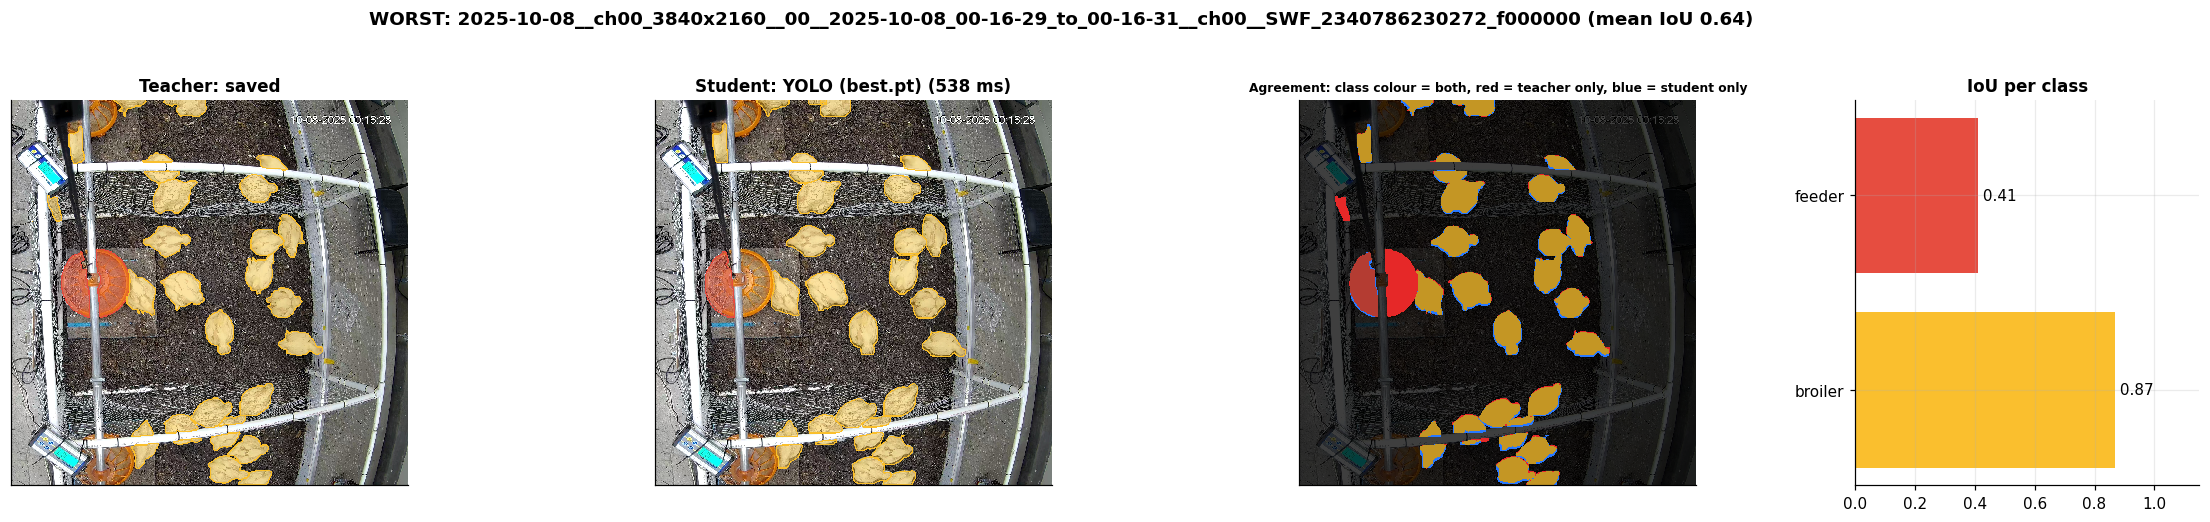

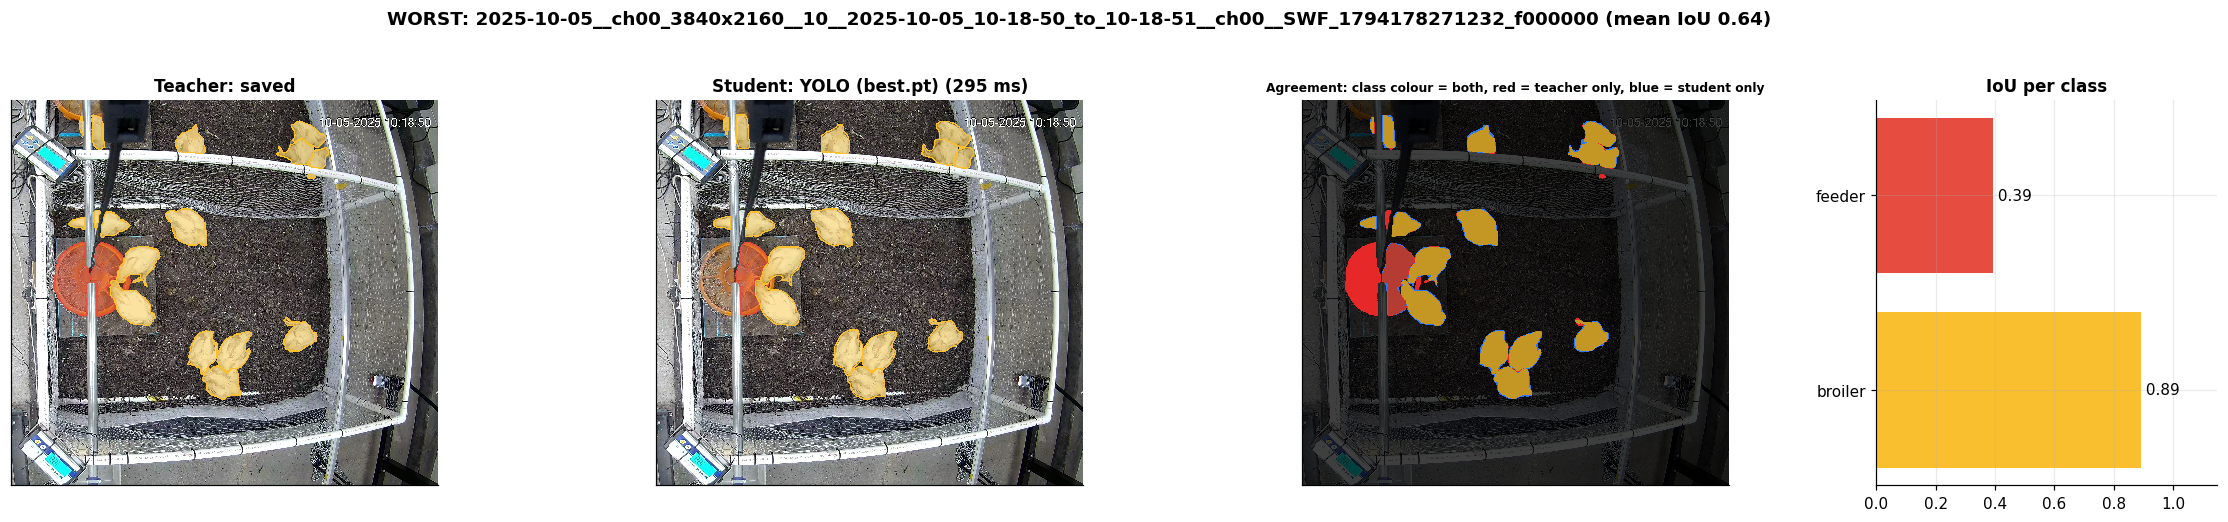

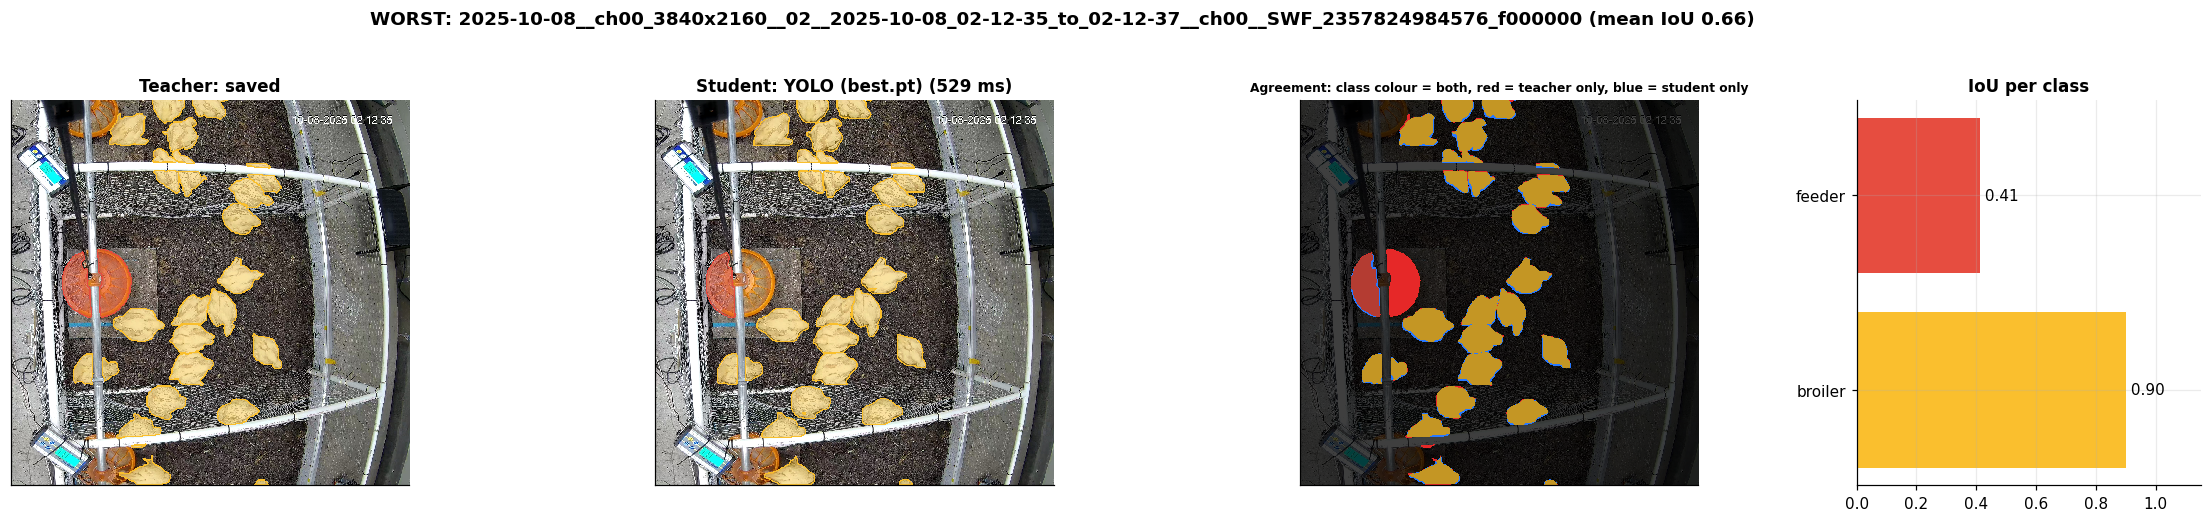

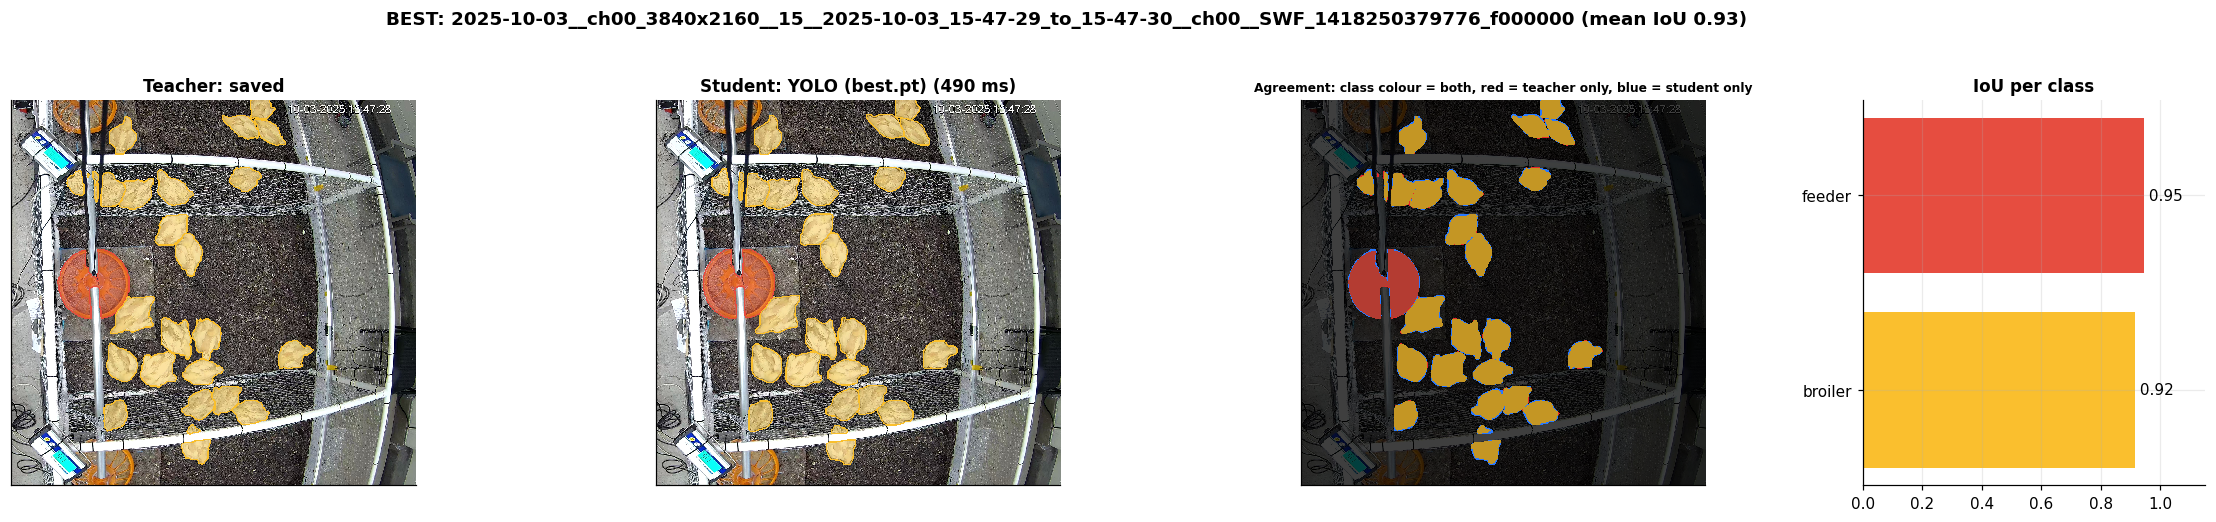

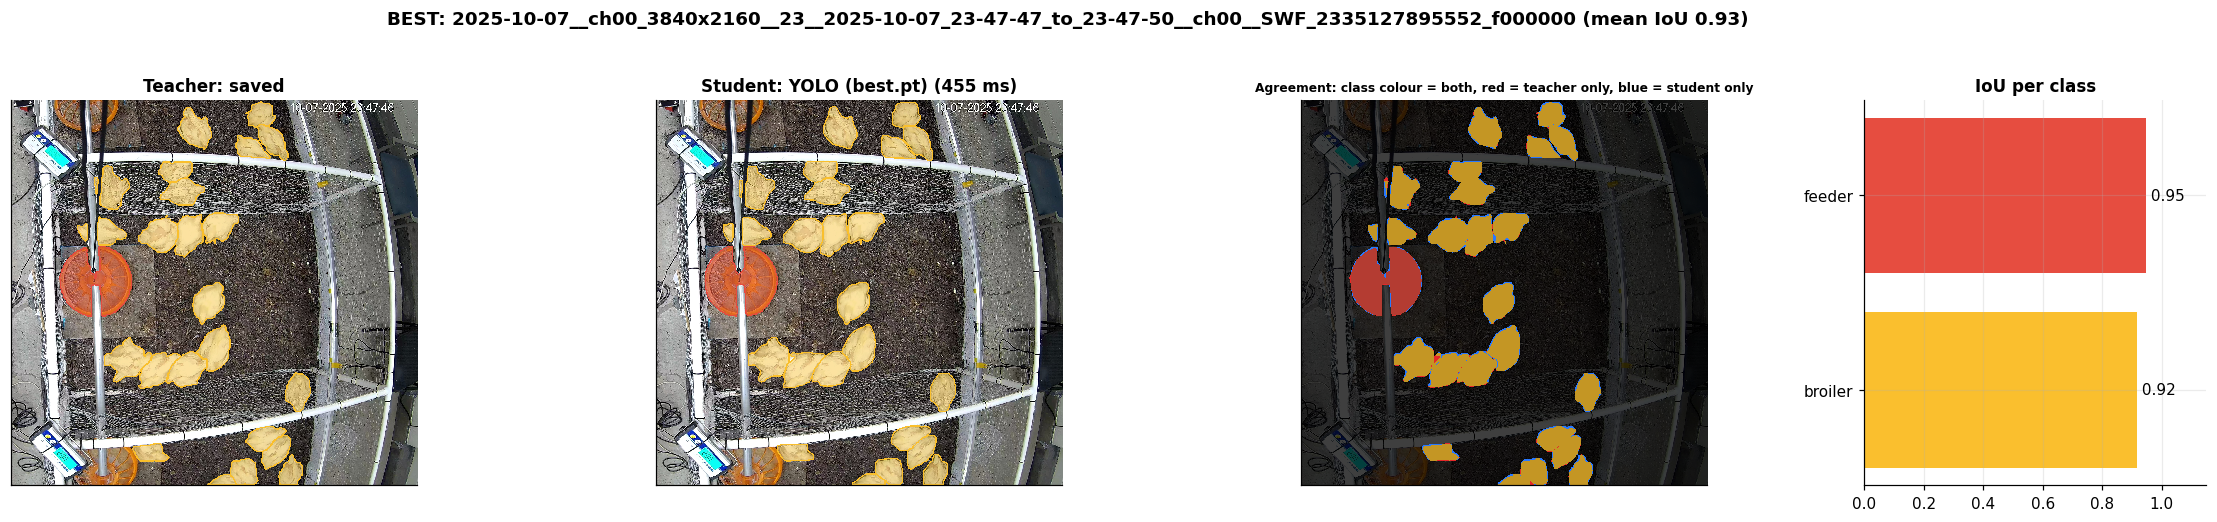

In [ ]:
STUDENT_WEIGHTS = Path(RUN_DIR) / "weights" / "best.pt" if RUN_DIR else None
metrics_rows, per_class = [], None
if STUDENT_WEIGHTS and STUDENT_WEIGHTS.is_file():
    from broilerseg.segmentation import YoloSegmenter
    student = YoloSegmenter(STUDENT_WEIGHTS, imgsz=IMGSZ)
    for split in ("val", "test"):
        if (YOLO_DIR / "images" / split).is_dir() and any((YOLO_DIR / "images" / split).iterdir()):
            m, pc = evaluate_student(STUDENT_WEIGHTS, YOLO_DIR / "data.yaml", split, IMGSZ)
            metrics_rows.append(m)
            per_class = pc if split == "test" or per_class is None else per_class
    display(pd.DataFrame(metrics_rows).round(3))
    show(viz.plot_student_metrics(metrics_rows, per_class), "student_metrics")
else:
    from broilerseg.synthetic import ColorSegmenter
    student = ColorSegmenter(); student.name = "stand-in student (no trained model)"
    print("No trained model - a stand-in student is used so the plots below still appear.")

held = ds[ds.split == ("test" if (ds.split == "test").any() else "val")].stem.tolist() or ds.stem.tolist()
held_images = load_frames_lazily(LABEL_DIR, held)      # read one at a time (memory)
agree, _ = teacher_student_table(held_images, teacher_results, student, keep=())
agree.to_csv(OUT / "teacher_student_agreement.csv", index=False)
display(agree.groupby("class_name").iou.describe().round(3))
show(viz.plot_iou_distribution(agree), "iou_distribution")
show(viz.plot_count_agreement(agree), "count_agreement")
per_img = agree.groupby("stem").iou.mean().sort_values()
for tag, ss in (("WORST", per_img.index[:3]), ("BEST", per_img.index[-2:])):
    for s in ss:
        show(viz.plot_teacher_student(held_images[s], teacher_results[s], student.segment(held_images[s]),
                                      f"{tag}: {s} (mean IoU {per_img[s]:.2f})"), f"ts_{tag.lower()}_{s[-12:]}")

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.115 🚀 Python-3.12.5 torch-2.8.0 CPU (Apple M3 Pro)
WARNING ⚠️ NCNN export does not support end2end models, disabling end2end branch.
YOLOv8n-seg summary (fused): 86 layers, 3,258,454 parameters, 0 gradients, 11.3 GFLOPs

PyTorch: starting from '/Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 38, 8400), (1, 32, 160, 160)) (6.5 MB)
requirements: Ultralytics requirement ['ncnn'] not found, attempting AutoUpdate...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/6.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━ 5.0/6.8 MB 34.9 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 32.9 MB/s  0:00:00

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip

requirements: AutoUpdate su

pnnxparam = /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model/model.pnnx.param
pnnxbin = /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model/model.pnnx.bin
pnnxpy = /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model/model_pnnx.py
pnnxonnx = /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model/model.pnnx.onnx
ncnnparam = /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model/model.ncnn.param
ncnnbin = /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model/model.ncnn.bin
ncnnpy = /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model/model_ncnn.py
fp16 = 0
optlevel = 2
device = cpu
inputshape = [

NCNN: export success ✅ 10.5s, saved as '/Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model' (12.6 MB)

Export complete (11.2s)
Results saved to /Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model
Predict:         yolo predict task=segment model=/Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model imgsz=640 
Validate:        yolo val task=segment model=/Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/runs/broiler_yolov8n_seg/weights/best_ncnn_model imgsz=640 data=/Users/akintanoreofeoluwa/broilerseg_outputs/02_distillation/yolo_dataset_2class/data.yaml  
Visualize:       https://netron.app
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.115 🚀 Python-3.12.5 torch-2.8.0 CPU (Apple M3 Pro)
YOLOv8n-seg summary (fused): 86 layers, 3,258,454 parameters

,name,ms_mean,ms_std,fps,n,iou,size_mb
0,SAM 3,29727.105,13787.642,0.034,3,1.000,3400.000
1,YOLO (best.pt),537.635,260.975,1.860,8,0.878,6.775
2,student ncnn,390.863,128.085,2.558,8,0.903,13.214
3,student onnx,408.487,128.404,2.448,8,0.903,13.288


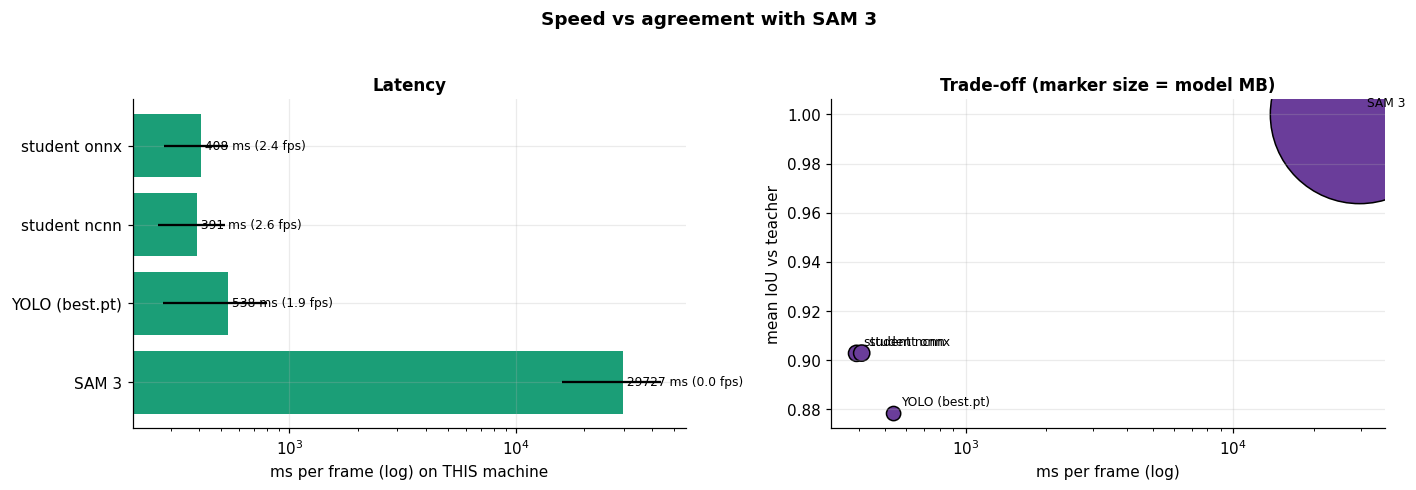

In [9]:
bench_imgs = [held_images[s] for s in list(held_images)[:8]]
rows = [{**benchmark(teacher, bench_imgs[:3], warmup=1), "iou": 1.0,
         "size_mb": 0.0 if DRY_RUN else {"sam3": 3400, "grounded_sam2": 1800}.get(TEACHER, 5200)},
        {**benchmark(student, bench_imgs, warmup=2), "iou": float(agree.iou.mean()),
         "size_mb": path_size_mb(STUDENT_WEIGHTS) if STUDENT_WEIGHTS else 0.0}]
EXPORTS = {}
if STUDENT_WEIGHTS and STUDENT_WEIGHTS.is_file():
    from broilerseg.segmentation import YoloSegmenter
    EXPORTS = export_for_raspberry_pi(STUDENT_WEIGHTS, IMGSZ, EXPORT_FORMATS)
    for fmt, path in EXPORTS.items():
        seg = YoloSegmenter(path, imgsz=IMGSZ)
        tab, _ = teacher_student_table({s: held_images[s] for s in list(held_images)[:8]},
                                       teacher_results, seg, keep=())
        rows.append({**benchmark(seg, bench_imgs, warmup=2), "name": f"student {fmt}",
                     "iou": float(tab.iou.mean()), "size_mb": path_size_mb(path)})
speed = pd.DataFrame(rows)
display(speed.round(3))
show(viz.plot_speed_accuracy(rows), "speed_accuracy")

## 8. Save the model for Notebook 3

Everything needed to use the student goes into one folder: the weights, the Pi exports, the dataset definition, the training curves, the pen regions (`pen_rois.csv`) and a `model_card.json` with the evaluation results. The card also stores **one typical pen region** (as fractions of the frame, so it fits the 4K stream and the 704 x 480 sub-stream of the same camera). `load_student` crops to it automatically, in Notebook 3 and on the Pi. **Notebook 3 asks for this folder.**

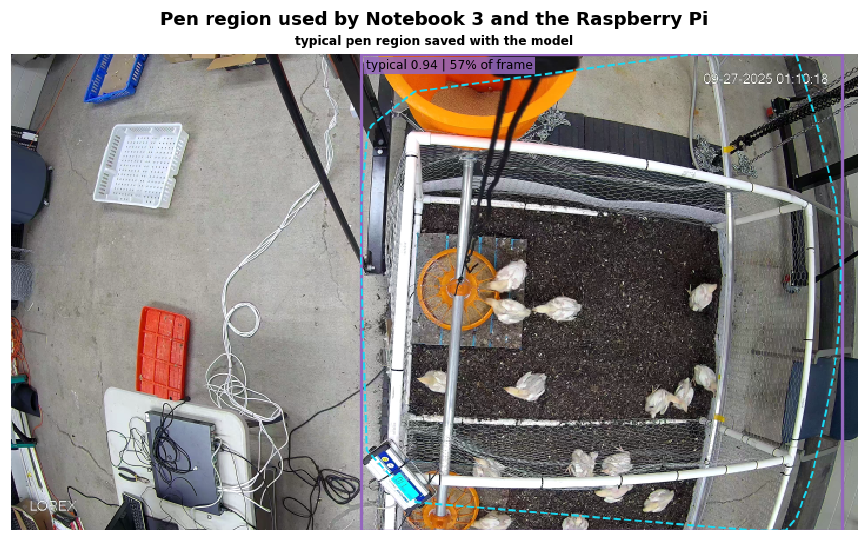

Saved model folder: /Users/akintanoreofeoluwa/broilerseg_models/broiler_yolov8n_seg
   args.yaml (0.0 MB)
   best.onnx (13.3 MB)
   best.pt (6.8 MB)
   best_ncnn_model (13.2 MB)
   model_card.json (0.0 MB)
   pen_rois.csv (2.1 MB)
   results.csv (0.0 MB)
   training (13.9 MB)

In Notebook 3 set  MODEL_DIR = '/Users/akintanoreofeoluwa/broilerseg_models/broiler_yolov8n_seg'


In [10]:
card = {"imgsz": IMGSZ, "base_model": BASE_MODEL, "epochs": EPOCHS, "teacher": teacher.name,
        "teacher_key": TEACHER, "split_by": SPLIT_BY, "frames_per_video": FRAMES_PER_VIDEO,
        "videos": int(videos.shape[0]), "folders": int(videos.folder.nunique()),
        "images": {k: int(v) for k, v in ds.split.value_counts().items()},
        "metrics": metrics_rows, "mean_iou_vs_teacher": float(agree.iou.mean()),
        "iou_per_class": agree.groupby("class_name").iou.mean().round(4).to_dict(),
        "student_ms_per_frame_here": float(speed.ms_mean.iloc[1]),
        "video_root": str(VIDEO_DIR), "stand_in": STUDENT_WEIGHTS is None,
        "only_resolution": list(ONLY_RESOLUTION) if ONLY_RESOLUTION else None,
        "pen_crop": bool(USE_PEN_CROP), "pen_roi": PEN_ROI.as_dict() if PEN_ROI else None,
        "pen_mask_outside": bool(PEN_MASK_OUTSIDE), "pen_prompts": list(PEN_PROMPTS),
        "pen_methods": rois.method.value_counts().to_dict() if rois is not None else {},
        "trained": datetime.now().isoformat(timespec="seconds")}
MODEL_DIR = save_student(RUN_DIR, MODELS, MODEL_NAME, EXPORTS, card)
if rois is not None:
    save_rois(rois, MODEL_DIR / "pen_rois.csv")
    show(viz.plot_pen_rois([frame0], [PEN_ROI], ["typical pen region saved with the model"], ncols=1,
                           size=5, title="Pen region used by Notebook 3 and the Raspberry Pi"), "saved_pen_roi")
print("Saved model folder:", MODEL_DIR)
for p in sorted(MODEL_DIR.iterdir()):
    print("  ", p.name, f"({path_size_mb(p):.1f} MB)")
print("\nIn Notebook 3 set  MODEL_DIR =", repr(str(MODEL_DIR)))

**Next:** open **Notebook 3**. It loads this saved model, segments with YOLO, fits the mass equation and estimates weights.

If the student disagrees with the teacher too often (section 7), label more frames (raise `FRAMES_PER_VIDEO`, add videos, fix the suspect frames in section 4), try `yolov8s-seg.pt`, or train at the image size you will deploy at.